# TASK #1: PROJECT OVERVIEW 


In [ ]:
# !pip install tensorflow

In [1]:
import matplotlib.pyplot as plt
import numpy as np
# import tensorflow as tf
import pandas as pd
import seaborn as sns
import pickle
import random

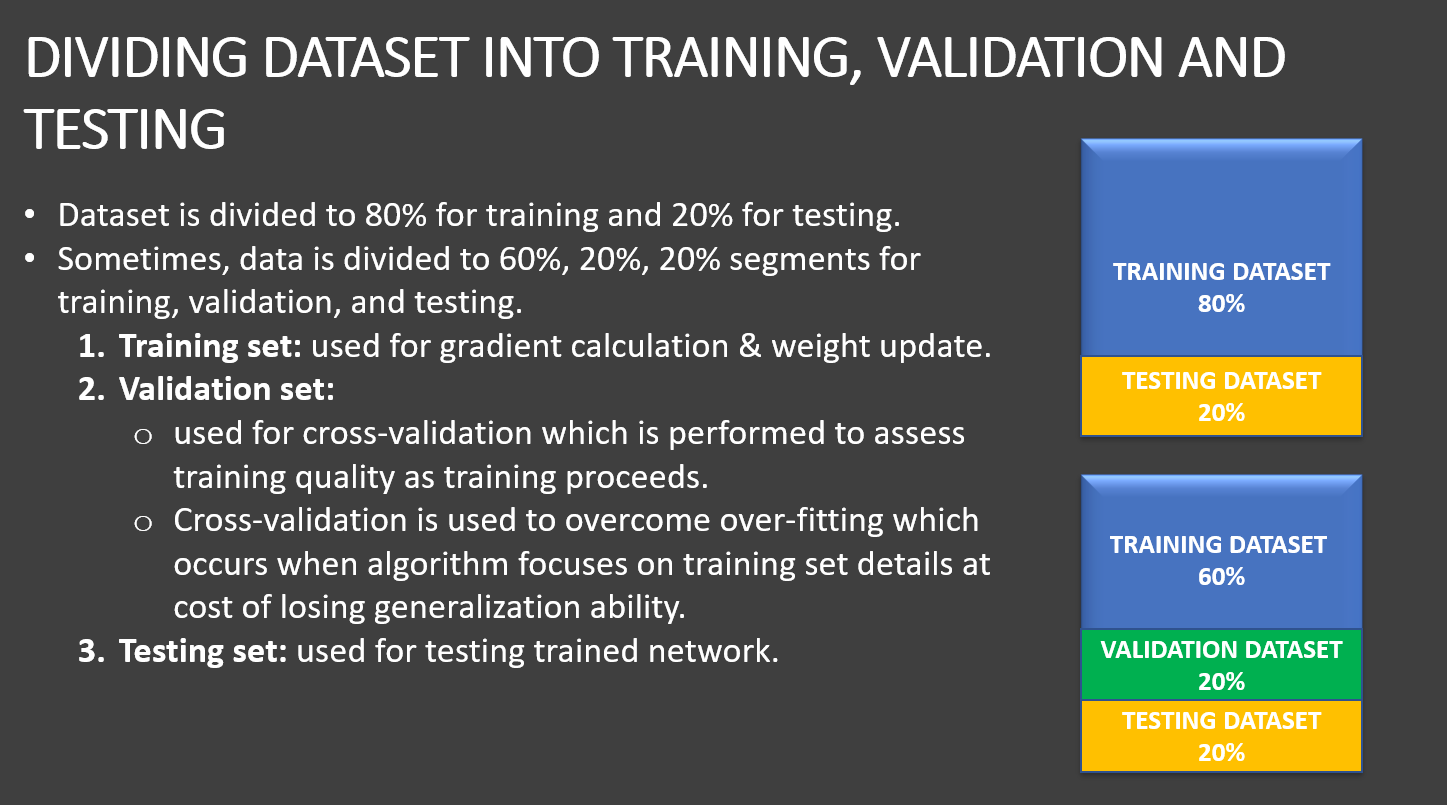

In [2]:
with open("./traffic-signs-data/train.p", mode='rb') as training_data:
    train = pickle.load(training_data)
with open("./traffic-signs-data/valid.p", mode='rb') as validation_data:
    valid = pickle.load(validation_data)
with open("./traffic-signs-data/test.p", mode='rb') as testing_data:
    test = pickle.load(testing_data)

In [3]:
X_train, y_train = train['features'], train['labels']
X_validation, y_validation = valid['features'], valid['labels']
X_test, y_test = test['features'], test['labels']

In [4]:
X_train.shape

(34799, 32, 32, 3)

In [5]:
y_train.shape

(34799,)

In [6]:
y_train

array([41, 41, 41, ..., 25, 25, 25], dtype=uint8)

# TASK #2: PERFROM IMAGES VISUALIZATION

1

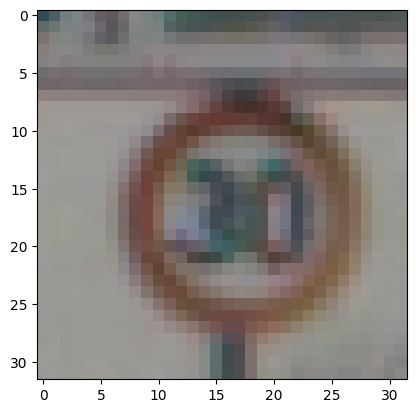

In [7]:
i = np.random.randint(1, len(X_train))
plt.imshow(X_train[i])
y_train[i]

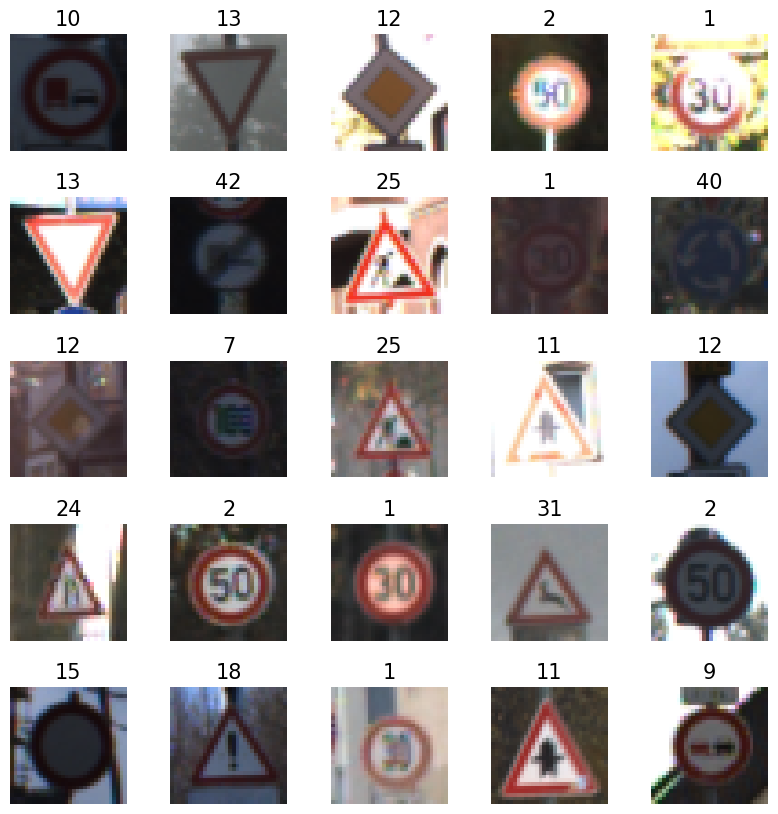

In [8]:
# Let's view more images in a grid format
# Define the dimensions of the plot grid 
W_grid = 5
L_grid = 5

# fig, axes = plt.subplots(L_grid, W_grid)
# subplot return the figure object and axes object
# we can use the axes object to plot specific figures at various locations

fig, axes = plt.subplots(L_grid, W_grid, figsize = (10,10))

axes = axes.ravel() # flaten the 15 x 15 matrix into 225 array

n_training = len(X_train) # get the length of the training dataset

# Select a random number from 0 to n_training
for i in np.arange(0, W_grid * L_grid): # create evenly spaces variables 

    # Select a random number
    index = np.random.randint(0, n_training)
    # read and display an image with the selected index    
    axes[i].imshow( X_train[index])
    axes[i].set_title(y_train[index], fontsize = 15)
    axes[i].axis('off')

plt.subplots_adjust(hspace=0.4)

        

# TASK #3: CONVERT IMAGES TO GRAYSCALE AND PERFORM NORMALIZATION

In [9]:
from sklearn.utils import shuffle
X_train, y_train = shuffle(X_train, y_train)

In [10]:
X_train_gray = np.sum(X_train/3, axis = 3, keepdims = True)
X_test_gray = np.sum(X_test/3, axis = 3, keepdims = True)
X_validation_gray = np.sum(X_validation/3, axis = 3, keepdims = True)

In [11]:
X_train_gray.shape


(34799, 32, 32, 1)

In [12]:
X_test_gray.shape


(12630, 32, 32, 1)

In [13]:
X_train_gray_norm = (X_train_gray - 128)/128
X_test_gray_norm = (X_test_gray - 128)/128
X_validation_gray_norm = (X_validation_gray - 128)/128

In [14]:
X_train_gray_norm

array([[[[-0.8359375 ],
         [-0.8515625 ],
         [-0.84114583],
         ...,
         [-0.828125  ],
         [-0.8359375 ],
         [-0.85416667]],

        [[-0.83333333],
         [-0.83333333],
         [-0.828125  ],
         ...,
         [-0.828125  ],
         [-0.83333333],
         [-0.84635417]],

        [[-0.84114583],
         [-0.83333333],
         [-0.83333333],
         ...,
         [-0.83333333],
         [-0.8359375 ],
         [-0.84114583]],

        ...,

        [[-0.85677083],
         [-0.8515625 ],
         [-0.8515625 ],
         ...,
         [-0.88541667],
         [-0.890625  ],
         [-0.890625  ]],

        [[-0.859375  ],
         [-0.8515625 ],
         [-0.84635417],
         ...,
         [-0.875     ],
         [-0.8828125 ],
         [-0.890625  ]],

        [[-0.86197917],
         [-0.85416667],
         [-0.85416667],
         ...,
         [-0.87760417],
         [-0.8828125 ],
         [-0.8828125 ]]],


       [[[-0.8046875 ],


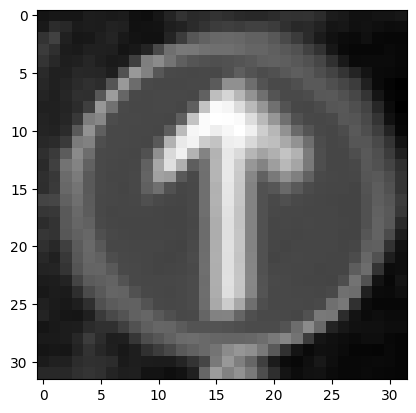

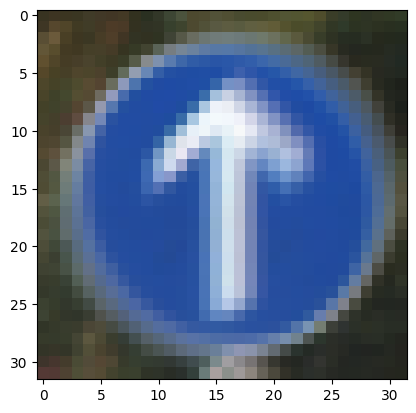

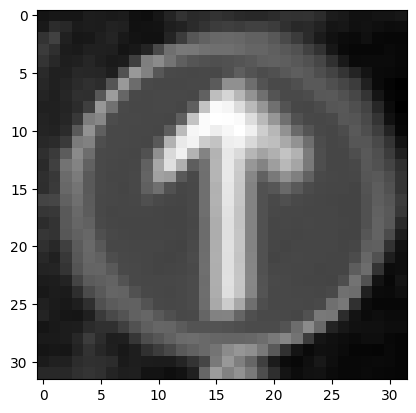

In [15]:
i = random.randint(1, len(X_train_gray))
plt.imshow(X_train_gray[i].squeeze(), cmap = 'gray')
plt.figure()
plt.imshow(X_train[i])
plt.figure()
plt.imshow(X_train_gray_norm[i].squeeze(), cmap = 'gray')

# TASK #4: BUILD DEEP CONVOLUTIONAL NEURAL NETWORK MODEL

In [1]:
!/opt/anaconda3/bin/pip install tensorflow

In [4]:
%pip install tensorflow

  Using cached tensorflow-2.16.2-cp39-cp39-macosx_10_15_x86_64.whl.metadata (4.1 kB)
  Using cached absl_py-2.3.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached h5py-3.14.0-cp39-cp39-macosx_10_9_x86_64.whl.metadata (2.7 kB)
  Using cached libclang-18.1.1-py2.py3-none-macosx_10_9_x86_64.whl.metadata (5.2 kB)
  Using cached ml_dtypes-0.3.2-cp39-cp39-macosx_10_9_universal2.whl.metadata (20 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-4.25.8-cp37-abi3-macosx_10_9_universal2.whl.metadata (541 bytes)
  Using cached termcolor-3.1.0-py3-none-any.whl.metadata (6.4 kB)
  Using cached grpcio-1.78.0.tar.gz (12.9 MB)
  Installing build dependencies ... done
  Getting requi

In [3]:
%pip install tensorflow

from tensorflow.keras import datasets, layers, models

CNN = models.Sequential()

CNN.add(layers.Conv2D(10, (5,5), activation = 'relu', input_shape = (32,32,1)))
CNN.add(layers.AveragePooling2D(pool_size=(2, 2)))

#CNN.add(layers.Dropout(0.2))

CNN.add(layers.Conv2D(16, (5,5), activation = 'relu'))
CNN.add(layers.AveragePooling2D(pool_size=(2, 2)))

CNN.add(layers.Flatten())

CNN.add(layers.Dense(120, activation = 'relu'))

CNN.add(layers.Dense(84, activation = 'relu'))

CNN.add(layers.Dense(43, activation = 'softmax'))
CNN.summary()

  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 11.9 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... ^C
Note: you may need to restart the kernel to use updated packages.


ModuleNotFoundError: No module named 'tensorflow'

# TASK #5: COMPILE AND TRAIN DEEP CNN MODEL

In [ ]:
CNN.compile(optimizer = 'Adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

In [ ]:
history = CNN.fit(X_train_gray_norm,
                 y_train, 
                 batch_size = 500,
                 epochs = 30,
                 verbose = 1,
                 validation_data = (X_validation_gray_norm, y_validation))

Epoch 1/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.9926 - loss: 0.0335 - val_accuracy: 0.8438 - val_loss: 0.8120
Epoch 2/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.9918 - loss: 0.0324 - val_accuracy: 0.8517 - val_loss: 0.7935
Epoch 3/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9905 - loss: 0.0365 - val_accuracy: 0.8660 - val_loss: 0.7298
Epoch 4/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9942 - loss: 0.0259 - val_accuracy: 0.8463 - val_loss: 0.8710
Epoch 5/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9943 - loss: 0.0238 - val_accuracy: 0.8639 - val_loss: 0.7677
Epoch 6/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9937 - loss: 0.0246 - val_accuracy: 0.8497 - val_loss: 0.7937
Epoch 7/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9903 - loss: 0.0328 - val_accuracy: 0.8483 - val_loss: 0.8694
Epoch 8/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9917 - loss: 0.0278 - val_accuracy: 0.8628 - v

# TASK #6: ASSESS TRAINED CNN MODEL PERFORMANCE 

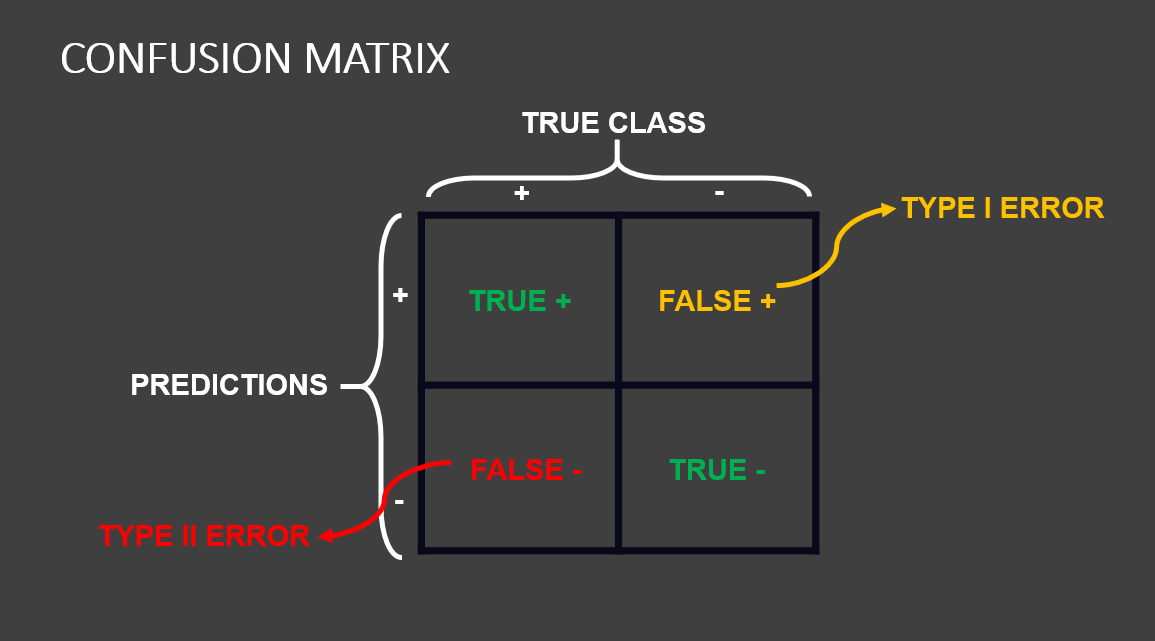

In [ ]:
score = CNN.evaluate(X_test_gray_norm, y_test)
print('Test Accuracy: {}'.format(score[1]))

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8552 - loss: 1.4563
Test Accuracy: 0.8551068902015686


In [1]:
history.history.keys()

NameError: name 'history' is not defined

In [22]:
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

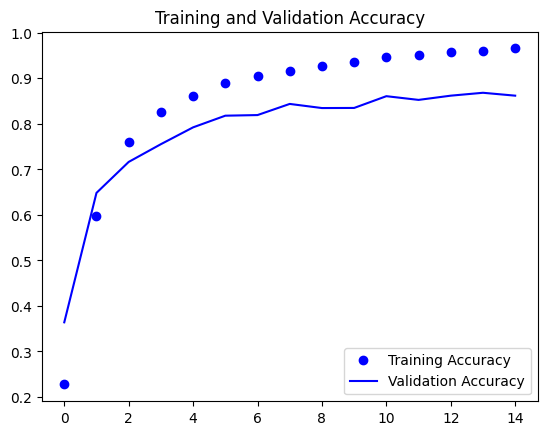

In [23]:
epochs = range(len(accuracy))

plt.plot(epochs, accuracy, 'bo', label='Training Accuracy')
plt.plot(epochs, val_accuracy, 'b', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

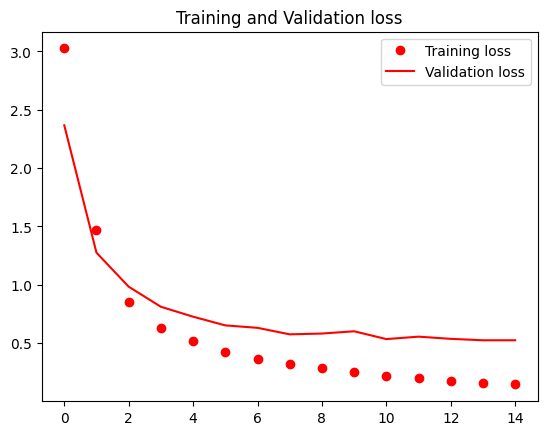

In [24]:
plt.plot(epochs, loss, 'ro', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and Validation loss')
plt.legend()

In [25]:
# predicted_classes = CNN.predict_classes(X_test_gray_norm)

y_prob = CNN.predict(X_test_gray_norm)          # shape: (N, 43)
predicted_classes = np.argmax(y_prob, axis=1)   # shape: (N,)
y_true = y_test

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


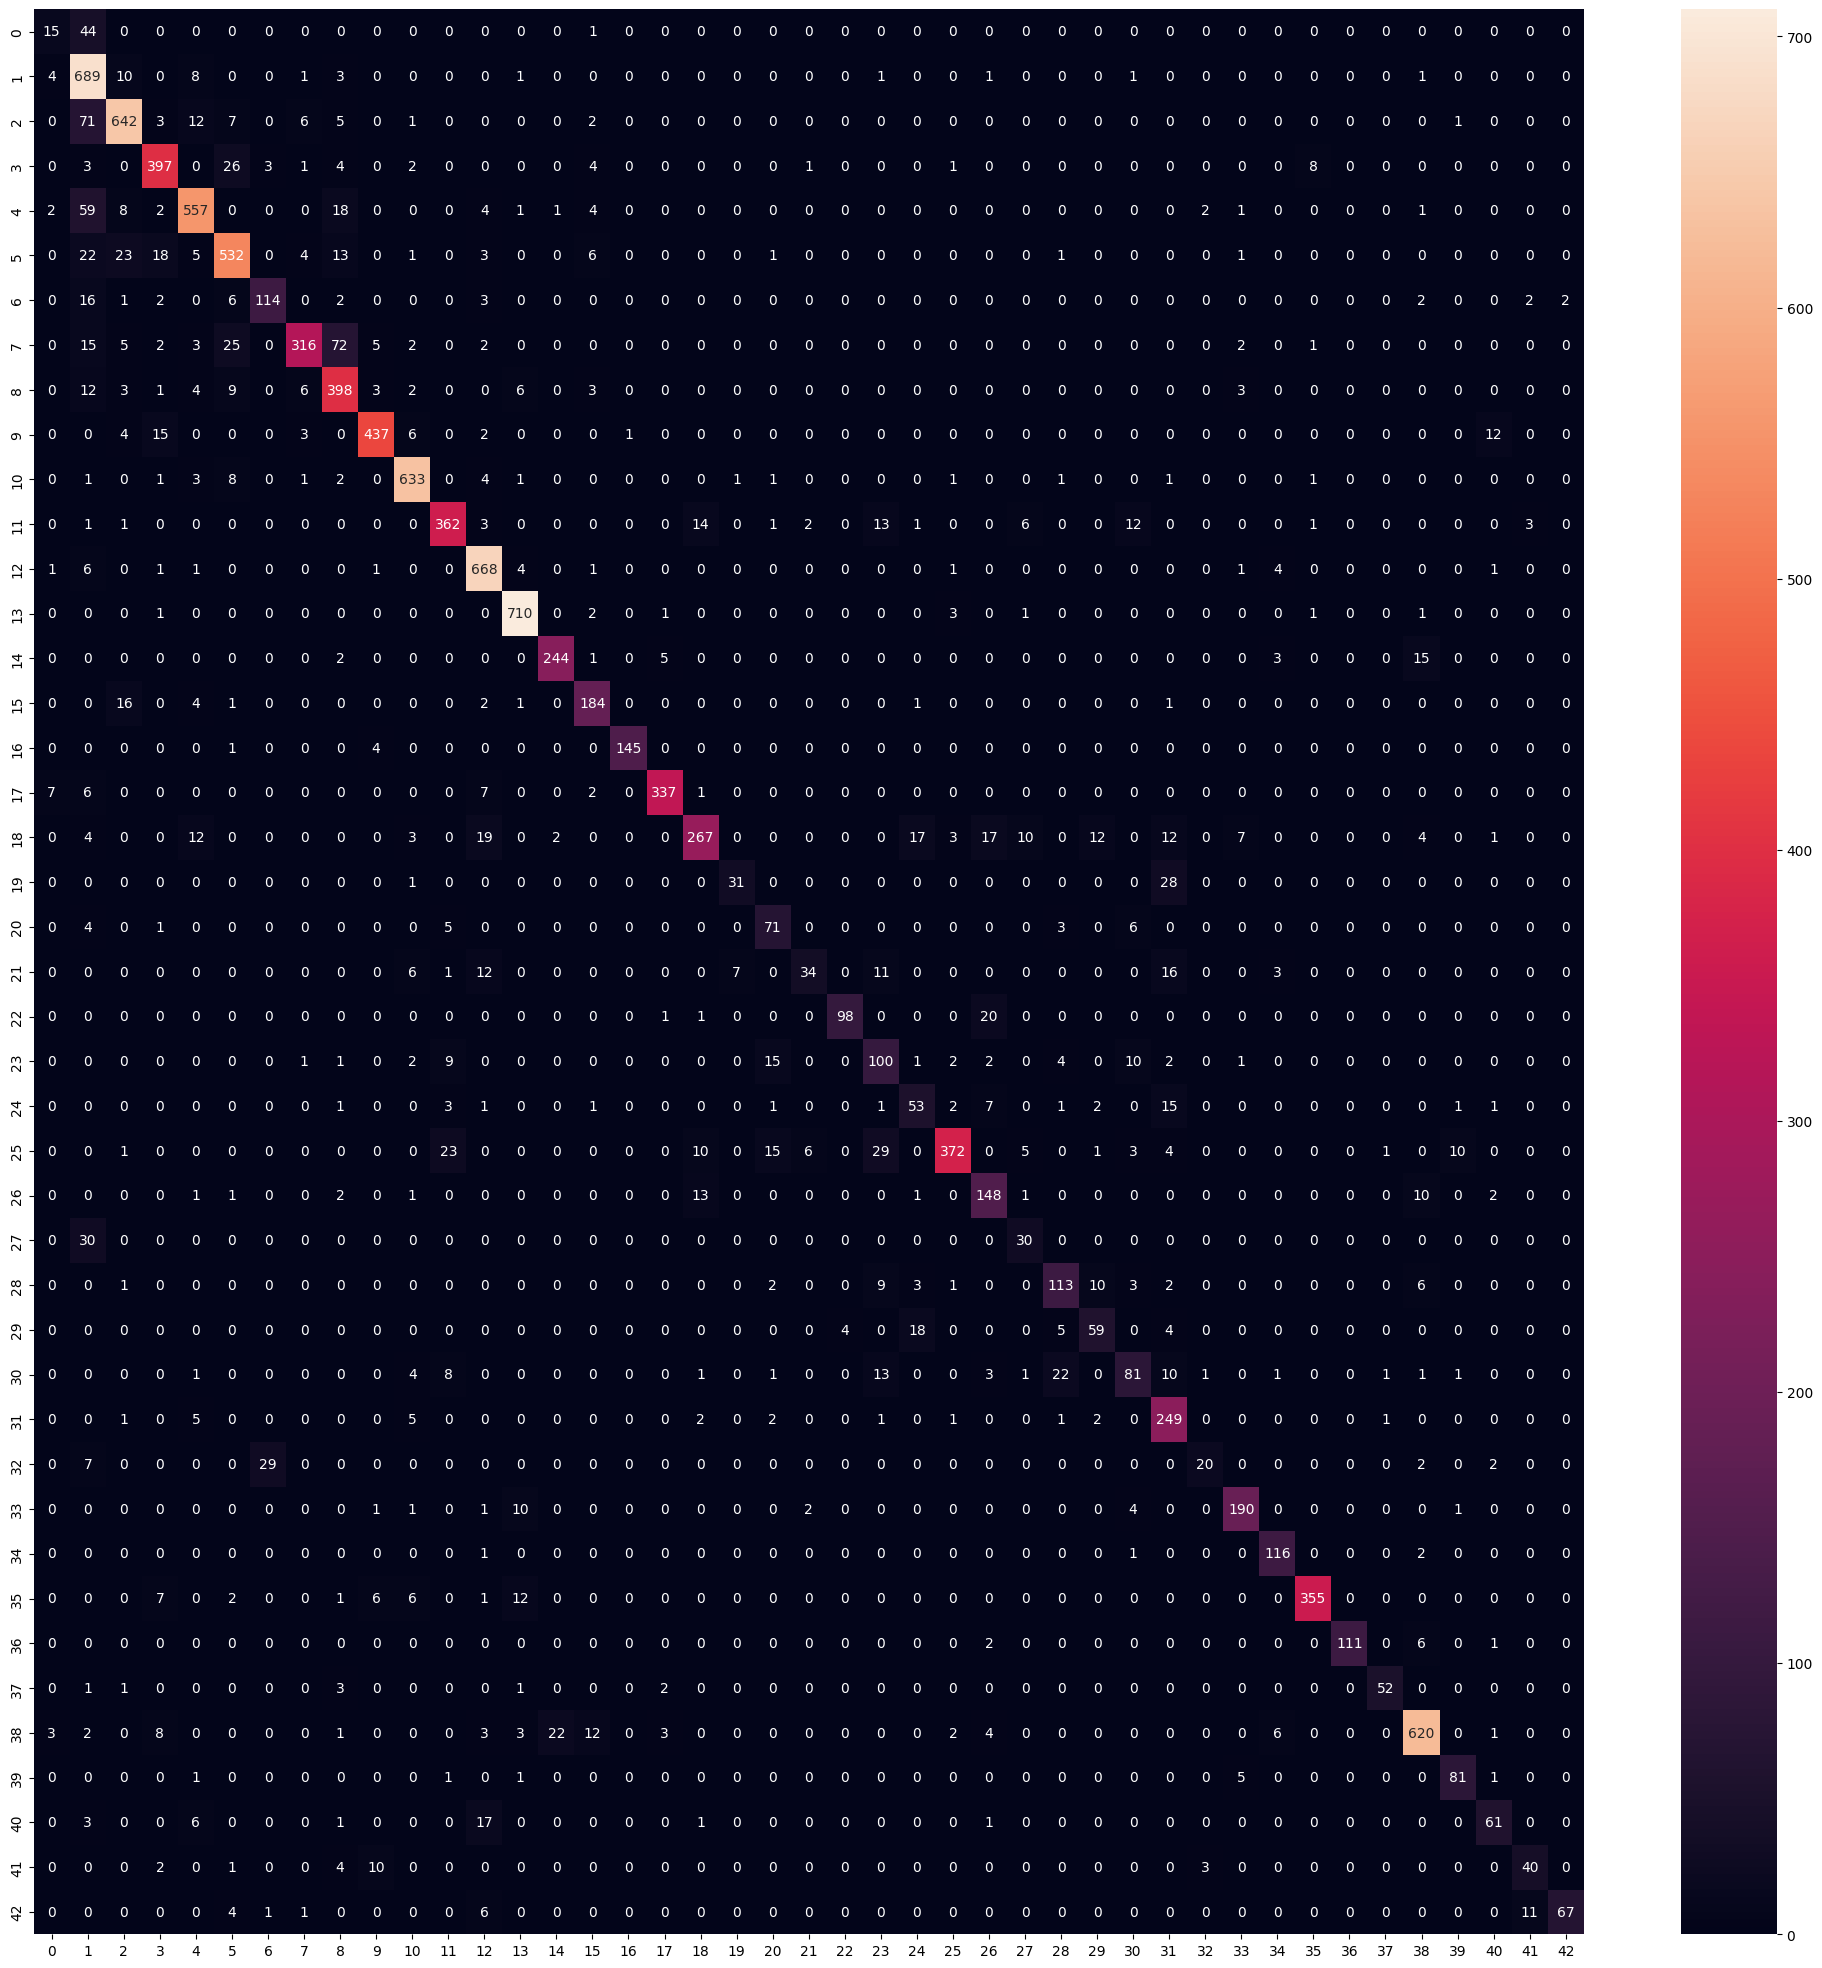

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, predicted_classes)
plt.figure(figsize = (25, 25))
sns.heatmap(cm, fmt="d", annot = True)

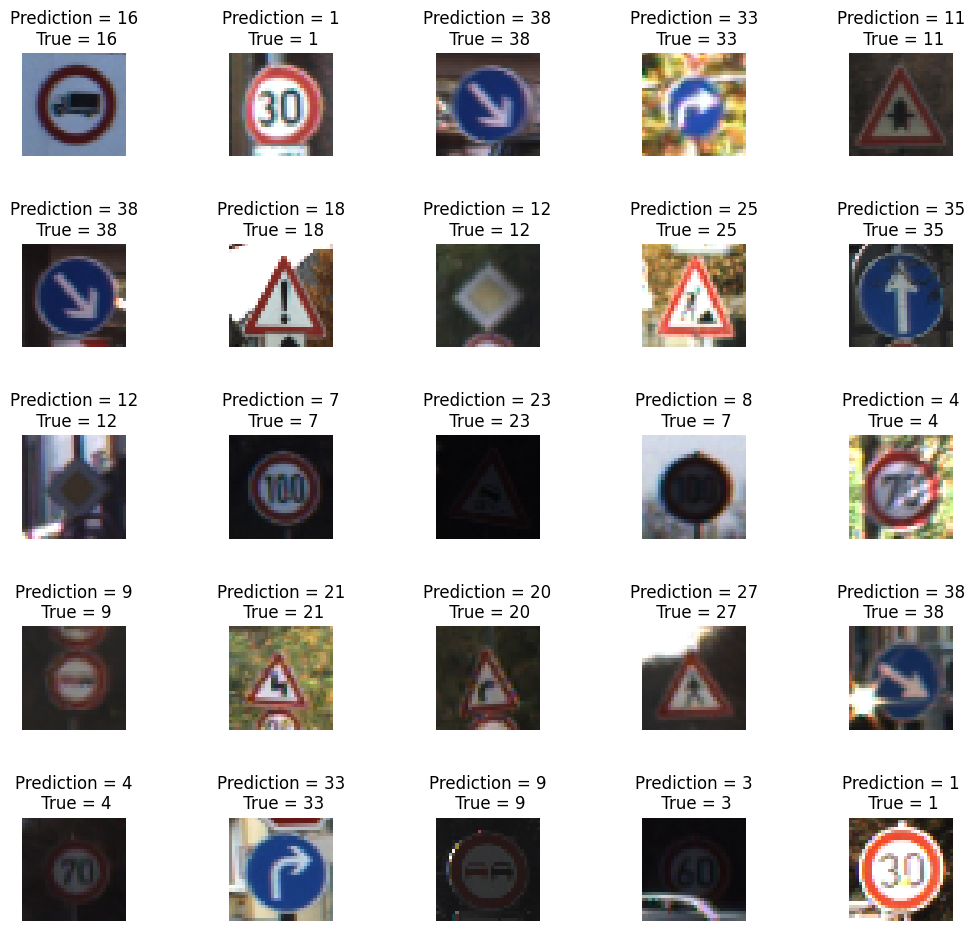

In [27]:
L = 5
W = 5

fig, axes = plt.subplots(L, W, figsize = (12, 12))
axes = axes.ravel()

for i in np.arange(0, L*W):
    axes[i].imshow(X_test[i])
    axes[i].set_title('Prediction = {}\n True = {}'.format(predicted_classes[i], y_true[i]))
    axes[i].axis('off')

plt.subplots_adjust(wspace = 1)    

# GREAT JOB!